## Imports

In [2]:
from matplotlib import pyplot as plt
import pandas as pd
import json
import random

## Data Loading and Cleaning

SFH = single family household

SFH34 wird rausgeschmissen, weil dieser abweichende Daten von den anderen aufweist. Konnte in den Plots festgestellt werden


In [3]:
#Load pickle into dataframe
hh_path = r"wattWise\local_input_data\1920 Final Data w. Additional Features HH Hourly Agg.pkl"
start_date = '2019-01-01'
end_date = '2019-12-31'
keyword = 'SFH'

data_allhouseholds = pd.read_pickle(hh_path)
mask = (data_allhouseholds.index >= start_date) & (data_allhouseholds.index < end_date)
data_allhouseholds = data_allhouseholds.loc[mask]

# Extract columns that contain the keyword in their name
filtered_df = data_allhouseholds.filter(like=keyword)
filtered_df = filtered_df.drop(columns=['SFH34_P_TOT'])
# turn unit to kWh
filtered_df = filtered_df/1000

print(filtered_df.head())

#print all column names
print(filtered_df.columns)


                           SFH3_P_TOT  SFH4_P_TOT  SFH5_P_TOT  SFH7_P_TOT  \
date                                                                        
2019-01-01 00:00:00+00:00    0.161493    0.378307    0.555783    0.472945   
2019-01-01 01:00:00+00:00    0.201888    0.379044    0.446765    0.303302   
2019-01-01 02:00:00+00:00    0.156627    0.381565    0.301362    0.142379   
2019-01-01 03:00:00+00:00    0.155399    0.427539    0.307746    0.152653   
2019-01-01 04:00:00+00:00    0.112611    0.309020    0.326347    0.208406   

                           SFH9_P_TOT  SFH12_P_TOT  SFH14_P_TOT  SFH16_P_TOT  \
date                                                                           
2019-01-01 00:00:00+00:00    0.276283     0.141515     1.263900     0.138280   
2019-01-01 01:00:00+00:00    0.254865     0.137292     1.251248     0.109699   
2019-01-01 02:00:00+00:00    0.198773     0.133582     1.121481     0.072142   
2019-01-01 03:00:00+00:00    0.241786     0.147410     0.990

#### Show some plots

In [4]:
# Loop through each column in filtered_df and plot the data
"""for column in filtered_df.columns:
    household_data = filtered_df[column]
    
    plt.figure(figsize=(20, 3))
    plt.plot(household_data.index, household_data.values, label=column)
    
    plt.xlabel('Time')
    plt.ylabel('Load [kWh]')
    plt.legend()
    plt.grid(True)
    plt.show()
"""

"for column in filtered_df.columns:\n    household_data = filtered_df[column]\n    \n    plt.figure(figsize=(20, 3))\n    plt.plot(household_data.index, household_data.values, label=column)\n    \n    plt.xlabel('Time')\n    plt.ylabel('Load [kWh]')\n    plt.legend()\n    plt.grid(True)\n    plt.show()\n"

## First Model Implementation. Assumption: Average Household 

1. Normalization of data ( so that every household has the same annual energy consumption):
- creating a new list with Household and annual consumption (adding up all the values based on this one year)
- Normalizing the values to a "average household" with 3000 kWh  

Output: _normalized_data_

2. Buidling average load profile of all households per hour 

3. Finding Base Load



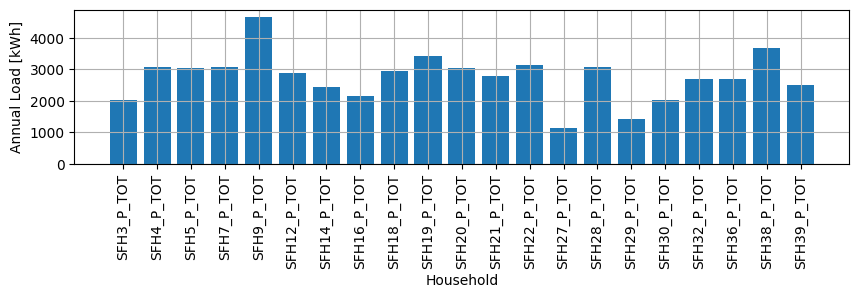

In [50]:
# 1. Normalization

# add all columns for each household and save it in a new table "householdname" AND "Householdname_annual_total"
data_annual_total_loads = pd.DataFrame()
for i in filtered_df.columns:
    data_annual_total_loads.loc['Annual Total', i] = filtered_df[i].sum()
#print(data_annual_total_loads)

#Plot of all annual household comsumptions (y-axis) for each household (x-axis), x axis values rotated by 90 degrees
plt.figure(figsize=(10, 2))
plt.bar(data_annual_total_loads.columns, data_annual_total_loads.loc['Annual Total'])
plt.xticks(rotation=90)
plt.xlabel('Household')
plt.ylabel('Annual Load [kWh]')
plt.grid(True)
plt.show()

# Normalization auf 3000kwH Houshehold
normalized_data = filtered_df.copy()
for i in filtered_df.columns:
    normalized_data[i] = filtered_df[i] / data_annual_total_loads.loc['Annual Total', i] * 3000
#print(normalized_data)


####

2999.9999999999986


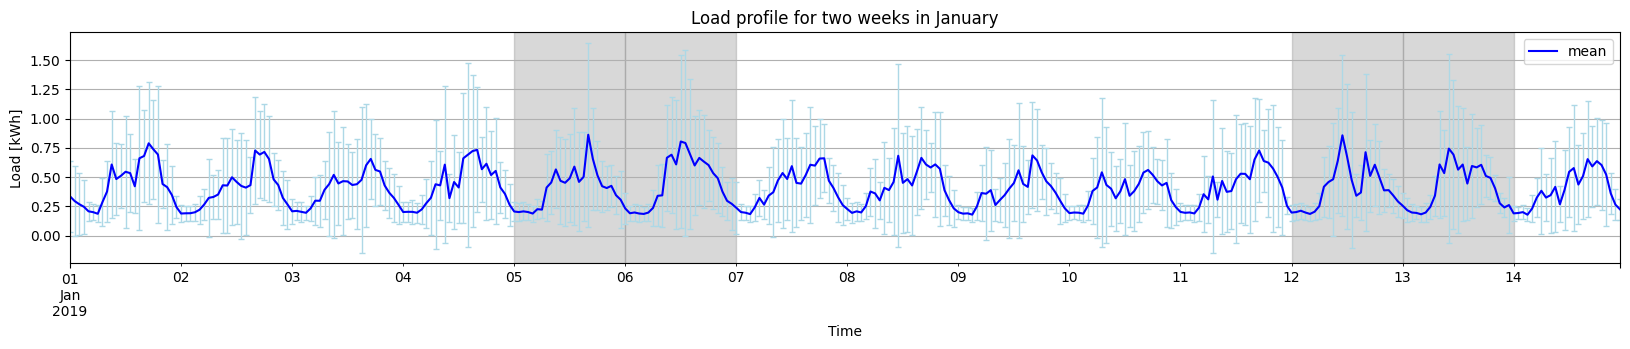

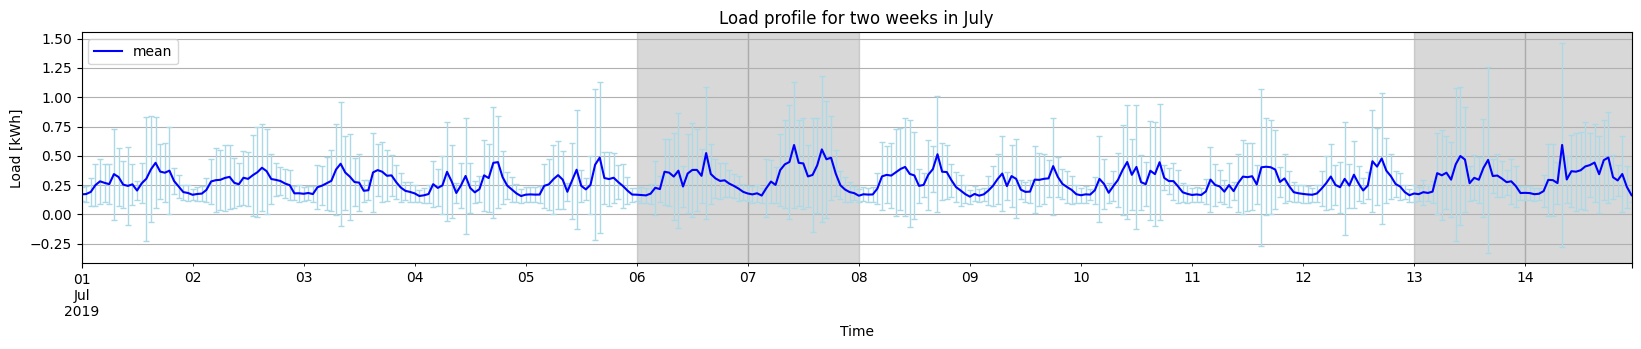

In [51]:
# 2. Buidling average load profile of all households per hour

# Calculate the mean of all households for each hour
average_hh_load_profile = normalized_data.mean(axis=1)

## Print the average load profile
#print(average_hh_load_profile)

#add standard deviation to the average load profile
std_dev = normalized_data.std(axis=1)
average_hh_load_profile = pd.concat([average_hh_load_profile, std_dev], axis=1)
average_hh_load_profile.columns = ['mean', 'std_dev']
#print(average_hh_load_profile)

#Test if the sum of the average load profile is 3000
sum = 0
for i in average_hh_load_profile['mean']: 
    sum += i

print(sum)  


# Plot for two weeks in January and mark grey if day is weekend
fig, ax = plt.subplots(figsize=(20, 3))
average_hh_load_profile['2019-01-01':'2019-01-14'].plot(y='mean', yerr='std_dev', ax=ax, color='blue', ecolor='lightblue', elinewidth=1, capsize=2)

# Mark weekends in grey
for day in pd.date_range(start='2019-01-01', end='2019-01-14'):
    if day.weekday() >= 5:  # 5 and 6 correspond to Saturday and Sunday
        ax.axvspan(day, day + pd.Timedelta(days=1), color='grey', alpha=0.3)

plt.title('Load profile for two weeks in January')
plt.xlabel('Time')
plt.ylabel('Load [kWh]')
plt.grid(True)
plt.show()

# Plot for two weeks in July and mark grey if day is weekend
fig, ax = plt.subplots(figsize=(20, 3))
average_hh_load_profile['2019-07-01':'2019-07-14'].plot(y='mean', yerr='std_dev', ax=ax, color='blue', ecolor='lightblue', elinewidth=1, capsize=2)

# Mark weekends in grey
for day in pd.date_range(start='2019-07-01', end='2019-07-14'):
    if day.weekday() >= 5:  # 5 and 6 correspond to Saturday and Sunday
        ax.axvspan(day, day + pd.Timedelta(days=1), color='grey', alpha=0.3)

plt.title('Load profile for two weeks in July')
plt.xlabel('Time')
plt.ylabel('Load [kWh]')
plt.grid(True)
plt.show()





### Load information for each Season on average of all households
- base load
- peak load

In [52]:
#Spring
spring_start = '2019-03-01'	
spring_end = '2019-05-31'
#Summer
summer_start = '2019-06-01'
summer_end = '2019-08-31'
#Autumn
autumn_start = '2019-09-01'
autumn_end = '2019-11-30'
#Winter
winter_start1 = '2019-01-01'
winter_end1 = '2019-02-28'
winter_start2 = '2019-12-01'	
winter_end2 = '2019-12-31'

base_load_spring = average_hh_load_profile[spring_start:spring_end]['mean'].min()
peak_load_spring = average_hh_load_profile[spring_start:spring_end]['mean'].max()

print('Spring base load:', base_load_spring)
print('Spring peak load:', peak_load_spring)

base_load_summer = average_hh_load_profile[summer_start:summer_end]['mean'].min()
peak_load_summer = average_hh_load_profile[summer_start:summer_end]['mean'].max()
print('Summer base load:', base_load_summer)
print('Summer peak load:', peak_load_summer)

base_load_autumn = average_hh_load_profile[autumn_start:autumn_end]['mean'].min()
peak_load_autumn = average_hh_load_profile[autumn_start:autumn_end]['mean'].max()
print('Autumn base load:', base_load_autumn)
print('Autumn peak load:', peak_load_autumn)


base_load_winter = (average_hh_load_profile[winter_start1:winter_end1]['mean'].min() + average_hh_load_profile[winter_start2:winter_end2]['mean'].min())*0.5
peak_load_winter = (average_hh_load_profile[winter_start1:winter_end1]['mean'].max() + average_hh_load_profile[winter_start2:winter_end2]['mean'].max())*0.5
print('Winter base load:', base_load_winter)
print('Winter peak load:', peak_load_winter)




Spring base load: 0.16081517227420825
Spring peak load: 0.8520695569373269
Summer base load: 0.15219640651008726
Summer peak load: 0.661503135290726
Autumn base load: 0.15414054077505757
Autumn peak load: 0.8805133488119036
Winter base load: 0.1688485369208198
Winter peak load: 0.8618687872262718


                           SFH3_P_TOT  weekday
date                                          
2019-01-01 00:00:00+00:00    0.238340  Tuesday
2019-01-01 01:00:00+00:00    0.297956  Tuesday
2019-01-01 02:00:00+00:00    0.231157  Tuesday
2019-01-01 03:00:00+00:00    0.229346  Tuesday
2019-01-01 04:00:00+00:00    0.166197  Tuesday
                           SFH3_P_TOT  weekday  hour
date                                                
2019-01-01 00:00:00+00:00    0.238340  Tuesday     0
2019-01-01 01:00:00+00:00    0.297956  Tuesday     1
2019-01-01 02:00:00+00:00    0.231157  Tuesday     2
2019-01-01 03:00:00+00:00    0.229346  Tuesday     3
2019-01-01 04:00:00+00:00    0.166197  Tuesday     4
                SFH3_P_TOT
weekday   hour            
Friday    0       0.198318
          1       0.229456
          2       0.230481
          3       0.237162
          4       0.239451
...                    ...
Wednesday 19      0.303254
          20      0.267048
          21      0.222841
   

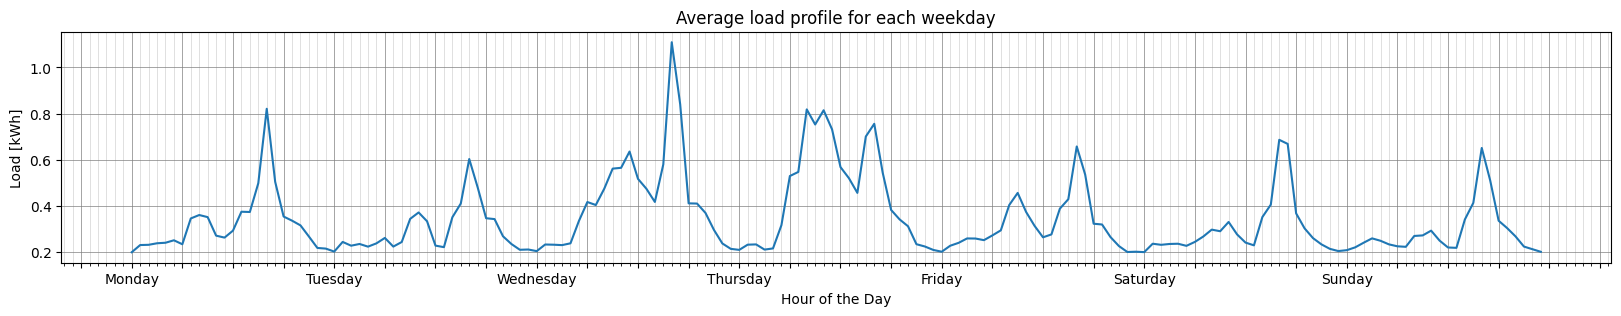

In [ ]:
# Testing household weekly average load profile for one household
example_household_data = normalized_data['SFH3_P_TOT']  # Replace 'SFH3_P_TOT' with the correct column name after identifying it
#print(example_household_data.head())

# Add column with the specific weekday
example_household_data = example_household_data.to_frame()
example_household_data['weekday'] = example_household_data.index.weekday
example_household_data['weekday'] = example_household_data['weekday'].apply(lambda x: ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'][x])
print(example_household_data.head())

# Add column with specific hour of the day
example_household_data['hour'] = example_household_data.index.hour
print(example_household_data.head())

# Calculate the mean load profile for each weekday and hour of the day
example_household_data_mean = example_household_data.groupby(['weekday', 'hour']).mean()
print(example_household_data_mean)


# Add to example_household_data_mean a column containing a specific date for each weekday and hour combination
example_household_data_mean['datetime'] = [pd.Timestamp(f'2023-01-0{(i % 7) + 1} {hour}:00:00') for i, (weekday, hour) in enumerate(example_household_data_mean.index)]
example_household_data_mean.set_index('datetime', inplace=True)
print(example_household_data_mean)


# Plot average week
fig, ax = plt.subplots(figsize=(20, 3))
example_household_data_mean.unstack(level=0).plot(ax=ax)
plt.title('Average load profile for each weekday')
plt.xlabel('Hour of the Day')
plt.ylabel('Load [kWh]')
ax.set_xticks(range(0, 24 * 7, 24))
ax.set_xticklabels(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])
plt.grid(True)

# Add a grid for the hours in light grey
ax.xaxis.set_major_locator(plt.MultipleLocator(1))
ax.xaxis.set_minor_locator(plt.MultipleLocator(1))
ax.grid(which='both', color='lightgrey', linestyle='-', linewidth=0.5)

# Make grid lines bold every 6 hours
ax.xaxis.set_major_locator(plt.MultipleLocator(6))
ax.grid(which='major', color='grey', linestyle='-', linewidth=0.5)

plt.show()



## Customer Data
- data_customer
- data_customer_load_profile_two_random_weeks
- customer_annual_electricity_consumption



#### Which infoirmation can be aggregated from this dataset? 
customer_annual_electricity_consumption 
- normalization value for model information 

data_customer_load_profile_two_random_weeks
- which season are we in?
- calculate average weekday behaviour and compare it with average weekday behavior of average household
- use this together with seasonal change for calculating yearly load prediction

-------------Information-------------
Information about the selected household SFH9_P_TOT:
Total annual consumption: 4661.779069749514 kWh
Selected two weeks: 2019-09-27 00:00:00+00:00 to 2019-10-11 00:00:00+00:00
The season for the selected two weeks is: Autumn
Base load of the customer household: 0.07888040017633441 kWh
Peak load of the customer household: 2.0936778660139583 kWh
-------------Plots-------------


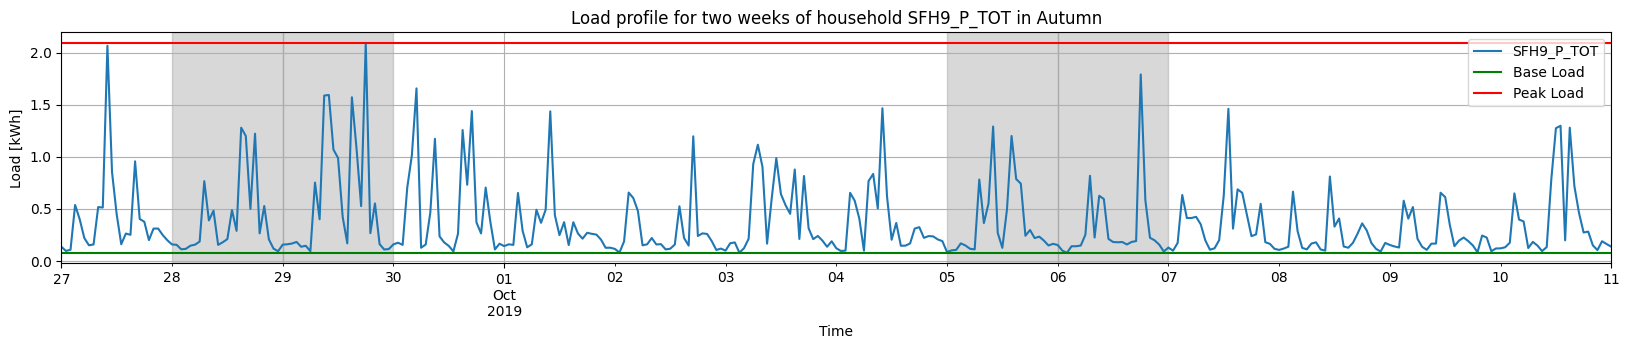

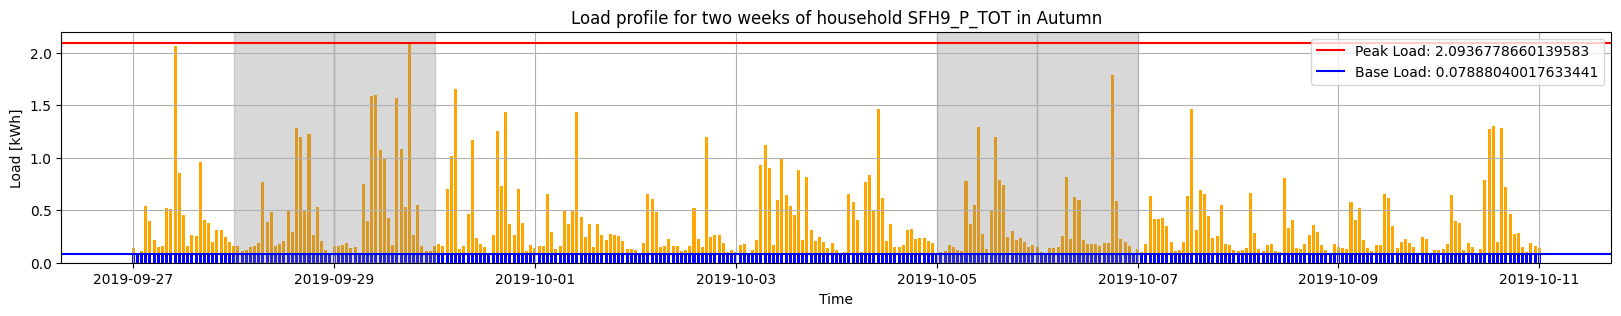

In [39]:
# Random Household Selection
# We take a random household as our customer household, the data here is already normalized. In a real dataset this needs to be done first! #TODO

random_household = random.choice(normalized_data.columns)
random_household = 'SFH9_P_TOT'  # Replace 'SFH9_P_TOT' with the column name after identifying it


# Extract the data for the selected random household
customer_household_data = normalized_data[random_household]

# randomly take two weeks of the household data
random_start_date = random.choice(pd.date_range(pd.Timestamp(start_date), pd.Timestamp(end_date) - pd.Timedelta(days=14), tz='UTC'))
random_end_date = random_start_date + pd.Timedelta(days=14)


#Filter data for the two weeks
customer_household_data = customer_household_data[random_start_date:random_end_date]
#Which season are we in?
def get_season(date):
    if date.month in [12, 1, 2]:
        return 'Winter'
    elif date.month in [3, 4, 5]:
        return 'Spring'
    elif date.month in [6, 7, 8]:
        return 'Summer'
    elif date.month in [9, 10, 11]:
        return 'Autumn'
season = get_season(random_start_date)

# Extract the annual electricity consumption of the selected random household (here 3000)
#TODO

#CAlculate base load over this two weeks. Base load is defined as die Leistung, die kontinuierlich benötigt wird und somit den minimalen Energiebedarf eeines HH.
#In einem Einfamilienhaus liegt die durchschnittliche Grundlast bei etwa 300 bis 400 Watt. Dieser meist vermeidbare Verbrauch wird in privaten Haushalten hauptsächlich durch das Nicht-Ausschalten oder das nicht vollständige Ausschalten von elektronischen Geräten verursacht.

base_load_customer = customer_household_data[customer_household_data.index].min()

# Calculate medium load
#medium_load_customer = customer_household_data[customer_household_data.index].median()
#print('Medium load of the customer household:', medium_load_customer)

# Calculate peak load
peak_load_customer = customer_household_data[customer_household_data.index].max()


#Print information about the selected household
print('-------------Information-------------')
print(f"Information about the selected household {random_household}:")
print(f"Total annual consumption: {data_annual_total_loads.loc['Annual Total', random_household]} kWh")
print(f"Selected two weeks: {random_start_date} to {random_end_date}")
print(f"The season for the selected two weeks is: {season}")
print('Base load of the customer household:', base_load_customer, 'kWh')
print('Peak load of the customer household:', peak_load_customer, 'kWh')
print('-------------Plots-------------')


#Plot load profile of the customer household with colors for base, medium and peak load.
fig, ax = plt.subplots(figsize=(20, 3))
customer_household_data.plot(ax=ax)
for day in pd.date_range(start=random_start_date, end=random_end_date):
    if day.weekday() >= 5:  # 5 and 6 correspond to Saturday and Sunday
        ax.axvspan(day, day + pd.Timedelta(days=1), color='grey', alpha=0.3)
plt.title(f'Load profile for two weeks of household {random_household} in {season}')
plt.xlabel('Time')
plt.ylabel('Load [kWh]')
plt.grid(True)
plt.axhline(y=base_load_customer, color='green', linestyle='-', label='Base Load')
#plt.axhline(y=medium_load_customer, color='yellow', linestyle='-', label='Medium Load')
plt.axhline(y=peak_load_customer, color='red', linestyle='-', label='Peak Load')
plt.legend()
plt.show()
# Plot load profile of the customer household with colors for base, medium, and peak load as a bar graph
fig, ax = plt.subplots(figsize=(20, 3))

# Define colors for different load levels
colors = ['blue', 'orange', 'red']

# Create a bar plot with different colors for base, medium, and peak load
for i in range(len(customer_household_data)):
    load = customer_household_data.iloc[i]
    if load <= base_load_customer:
        ax.bar(customer_household_data.index[i], load, color=colors[0], width=0.03)
    elif load <= peak_load_customer:
        ax.bar(customer_household_data.index[i], base_load_customer, color=colors[0], width=0.03)
        ax.bar(customer_household_data.index[i], load - base_load_customer, bottom=base_load_customer, color=colors[1], width=0.03)
plt.axhline(y=peak_load_customer, color='red', linestyle='-', label='Peak Load: ' + str(peak_load_customer))  
plt.axhline(y=base_load_customer, color='blue', linestyle='-', label='Base Load: ' + str(base_load_customer))
#plt.axhline(y=medium_load_customer, color='yellow', linestyle='-', label='Medium Load: ' + str(medium_load_customer))

# Mark weekends in grey
for day in pd.date_range(start=random_start_date, end=random_end_date):
    if day.weekday() >= 5:  # 5 and 6 correspond to Saturday and Sunday
        ax.axvspan(day, day + pd.Timedelta(days=1), color='grey', alpha=0.3)

plt.title(f'Load profile for two weeks of household {random_household} in {season}')
plt.xlabel('Time')
plt.ylabel('Load [kWh]')
plt.grid(True)
plt.legend()
plt.show()


#Average weekday of customer household two week data



In [40]:
customer_household_data

date
2019-09-27 00:00:00+00:00    0.137695
2019-09-27 01:00:00+00:00    0.097254
2019-09-27 02:00:00+00:00    0.108173
2019-09-27 03:00:00+00:00    0.537909
2019-09-27 04:00:00+00:00    0.399811
                               ...   
2019-10-10 20:00:00+00:00    0.150673
2019-10-10 21:00:00+00:00    0.104987
2019-10-10 22:00:00+00:00    0.190216
2019-10-10 23:00:00+00:00    0.162674
2019-10-11 00:00:00+00:00    0.137565
Freq: h, Name: SFH9_P_TOT, Length: 337, dtype: float64

In [44]:
customer_household_data = customer_household_data.to_frame(name='Load')
customer_household_data['Weekday'] = customer_household_data.index.weekday
customer_household_data['Weekday'] = customer_household_data['Weekday'].apply(lambda x: ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'][x])


AttributeError: 'DataFrame' object has no attribute 'to_frame'

# EXTRA

# Model
    def calculate_customer_load_profile(df_database_load_profiles, df_customer_profile_two_weeks, customer_anual_consumption):
        """
        Calculate the load profile of a customer based on the load profiles of similar households.

        Parameters:
        - df_database_load_profiles: DataFrame, the DataFrame containing the load profiles of similar households on an hourly basis.
        - df_customer_profile_two_weeks: DataFrame, the DataFrame containing the load profile of the customer for two weeks on an hourly basis.
        - customer_anual_consumption: float, the annual consumption of the customer.

        Returns:
        - DataFrame containing the hourly load profile of the customer for the whole year.
        """
        #TODO
        
        #Regression over df_database_load_profiles to find seasonal and daily patterns in load profiles. Output: load profiel for the whole year based on database


        #Regression over df_customer_profile_two_weeks to predict the load profile for the whole year. Output: load profile for the whole year based on customer data (two weeks)


        #Compare those two load profiles


        #Apply the regression model to the df_customer_profile_two_weeks to predict the load profile for the whole year


        return df_customer_profile
        



# Testing
    def comparing_real_profile_with_predicted_profile(df_real_profile, df_predicted_profile, df_dynamic_price):
        """
        Compare the real load profile with the predicted load profile and calculate the costs for the customer.

        Parameters:
        - df_real_profile: DataFrame, the DataFrame containing the real load profile of the customer on an hourly basis.
        - df_predicted_profile: DataFrame, the DataFrame containing the predicted load profile of the customer on an hourly basis.
        - df_dynamic_price: DataFrame, the DataFrame containing the dynamic price of electricity on an hourly basis.

        Returns:
        - float, the costs for the customer based on the dynamic price of electricity.
        - bool, True if the predicted load profile is accurate, False otherwise.
        """
        #TODO: Write the code

        #Compare the real load profile with the predicted load profile on an hourly basis. True, if the predicted load profile is accurate, False otherwise.
        #Accurate means error < xxx% #TODO: Define the error.

        #Calculate the costs for the customer based on the dynamic price of electricity. The costs are the sum of the product of the predicted load profile and the dynamic price of electricity on an hourly basis.
        


        return costs












def main():
    start_date = '2019-01-01'
    end_date = '2019-12-31'

    #Local Electricity Consumption Data
    hh_path = r"wattWise\local_input_data\1920 Final Data w. Additional Features HH Hourly Agg.pkl"
    keyword = 'SFH'
    sfh_columns_df = load_and_filter_dataframe(hh_path, keyword, start_date, end_date)
    available_household_loads = sfh_columns_df
    print("Those are available household loads:", available_household_loads)

    #Plot Test Household
    #plot_load_profile(available_household_loads, 'SFH3_P_TOT')

if __name__ == "__main__":
    main()


